# Thermal dynamic model of a two-zone flat: bedroom and toilet

**Course:** EVA_CE4IB: Dynamic Models for Building Energy Management

**Authors:** Mohamad Youness, Marcel Stranz, Parisa Parand

**Date:** November 2026

---

## Contents

1. Description of the building
2. Hypotheses
3. Thermal model
4. Mathematical model
5. Implementation in Python
6. Steady-state results
7. Dynamic simulation: step response
8. Dynamic simulation: response to weather
9. Optimization
10. Conclusions

## 1. Description of the building

The building is part of a flat with two thermal zones: a **bedroom** (zone 1) and a **toilet** (zone 2). North is at the top of the plan.

![Floor plan](Architecture_Plan.png)

| | Bedroom | Toilet |
|---|---|---|
| Floor dimensions | 4.11 m × 3.43 m (13'6" × 11'3") | 3.05 m × 1.22 m (10' × 4') |
| Ceiling height | 2.84 m | 2.84 m |
| Air volume | 40.1 m³ | 10.6 m³ |
| Exterior walls | west and south, 17.1 m² opaque | west, 2.9 m² opaque |
| Glazing | balcony door W2, south, 1.83 m × 2.39 m, double glazing | window W4, west, 0.90 m × 0.60 m, single glazing |

The two zones share a 10 cm concrete wall (7.1 m² without the door) with a closed door D3 (0.76 m × 2.03 m).

**Materials**

| Layer | $\lambda$ / W·m⁻¹·K⁻¹ | $\rho$ / kg·m⁻³ | $c$ / J·kg⁻¹·K⁻¹ | width / m |
|---|---|---|---|---|
| Concrete, exterior walls | 1.4 | 2300 | 880 | 0.229 |
| External insulation | 0.027 | 55 | 1210 | 0.08 |
| Concrete, shared wall | 1.4 | 2300 | 880 | 0.102 |

The properties of concrete and insulation are those of the course book (toy model house).

## 2. Hypotheses

**Location and weather.** Wädenswil (ZH), Switzerland, typical meteorological year file `CHE_ZH_Wadenswil.066730_TMYx.2011-2025.epw`.

**Boundary conditions.**
- The west and south walls are in contact with the outdoor air at temperature $T_o$ and are insulated on the outside.
- The east wall, the north wall of the toilet, the floor and the ceiling are next to heated spaces at a similar temperature. They are considered adiabatic and are not modelled.
- The door D3 and the balcony door W2 are closed.
- A concrete slab above the balcony shades the south façade. Half of the solar radiation is assumed to reach the south wall and the balcony door (`f_shade = 0.5`).

**Heat transfer.**
- Heat transfer is one-dimensional through the walls. Each concrete wall is one layer with one capacity in its middle.
- The heat capacity of the insulation, of the glass and of the air is neglected. The capacity of the insulation is about 1 % of that of the concrete.
- Outdoor surfaces: combined convection and radiation coefficient $h_o = 25$ W·m⁻²·K⁻¹.
- Indoor surfaces: convection only, $h_{cv} = 2.5$ W·m⁻²·K⁻¹. Long-wave radiation is modelled separately, between each glazing and the walls of its room. Radiation between the walls of a room is neglected because these surfaces have almost the same temperature.
- Infiltration: 0.5 air changes per hour in both rooms.

**Usage.** Internal gains of 100 W in the bedroom (one person and small devices), constant. Set point 20 °C in both rooms.

**Controller.** Each room has an ideal heating and cooling system modelled as a proportional controller with gain $K_p = 10^4$ W·K⁻¹.

## 3. Thermal model

The thermal circuit has **13 temperature nodes** ($\theta_0 \dots \theta_{12}$) and **25 flow-rate branches** ($q_0 \dots q_{24}$).

![Thermal circuit](Thermal_Circuit.png)

**Nodes.** $\theta_3$ is the bedroom air and $\theta_7$ the toilet air. $\theta_0,\theta_1,\theta_2$ are the outer surface, the middle and the inner surface of the bedroom exterior wall; $\theta_4,\theta_5,\theta_6$ belong to the shared wall; $\theta_8,\theta_9,\theta_{10}$ to the toilet exterior wall. $\theta_{11}$ and $\theta_{12}$ are the inner glass surfaces of W2 and W4. Only $\theta_1$, $\theta_5$ and $\theta_9$ have a capacity.

**Conductances.**

| Phenomenon | Expression |
|---|---|
| Convection | $G = h\,S$ |
| Conduction through a layer of width $w$ | $G = \dfrac{\lambda}{w}\,S$ |
| Advection (infiltration) | $G = \rho_a c_a \dot V$, with $\dot V = \mathrm{ACH}\cdot V / 3600$ |
| Long-wave radiation, glass (1) to wall (2) | $G_{LW} = \dfrac{4\sigma \bar T^3}{\dfrac{1-\varepsilon_1}{\varepsilon_1 S_1} + \dfrac{1}{S_1 F_{12}} + \dfrac{1-\varepsilon_2}{\varepsilon_2 S_2}}$ |
| P-controller | $G = K_p$ |
| Elements in series | $G = \left(\sum_i 1/G_i\right)^{-1}$ |

with $\sigma = 5.67\cdot10^{-8}$ W·m⁻²·K⁻⁴, $\bar T = 293.15$ K, $\varepsilon_{wall} = 0.85$, $\varepsilon_{glass} = 0.90$. The view factor from a glazing to each of the two walls of its room is estimated by the share of wall area.

The insulation is placed in series with half of the concrete in $q_1$ and $q_{10}$. Each glazing is described by its rated $U$-value (2.8 W·m⁻²·K⁻¹ for the double glazing, 5.8 W·m⁻²·K⁻¹ for the single glazing); the standard surface resistances $R_{si} = 0.13$ and $R_{se} = 0.04$ m²·K·W⁻¹ are removed to obtain the conductance of the glazing core, so that the inner glass surface becomes a node.

**Capacities.** $C = \rho\, c\, w\, S$ for each concrete wall.

**Sources.** Temperature sources: outdoor temperature $T_o$ (branches $q_0, q_{11}, q_{13}, q_{17}, q_{18}, q_{22}$) and set points $T_{sp}$ ($q_{23}, q_{24}$). Flow-rate sources: absorbed solar radiation on the outer wall surfaces, on the glass and on the indoor wall surfaces, and internal gains on the air nodes.

## 4. Mathematical model

**Differential-algebraic equations (DAE).**

$$C\,\dot\theta = -A^{T} G A\,\theta + A^{T} G\, b + f$$

- $A$ (25 × 13): incidence matrix; $-1$ where a branch leaves a node, $+1$ where it enters.
- $G$ (25 × 25): diagonal matrix of conductances.
- $C$ (13 × 13): diagonal matrix of capacities, with three non-zero elements.
- $b$ (25): temperature sources on the branches.
- $f$ (13): flow-rate sources in the nodes.

**State-space representation.** Eliminating the nodes without capacity gives

$$\dot\theta_C = A_s\,\theta_C + B_s\,u, \qquad y = C_s\,\theta_C + D_s\,u$$

with 3 states (the wall temperatures $\theta_1, \theta_5, \theta_9$), the input vector $u = [b_T^{T}, f_Q^{T}]^{T}$ of the non-zero sources and the outputs $y = [\theta_3, \theta_7]^{T}$. The conversion is done by `dm4bem.tc2ss`.

## 5. Implementation in Python

### 5.1 Parameters

In [463]:
# 0.1 imports
import numpy as np
import pandas as pd

In [464]:
# 0.2 geometry (from the floor plan)
ft = 0.3048
H = 2.8448                              # ceiling height, m

Lb_ew, Lb_ns = 13.5 * ft, 11.25 * ft   # bedroom 13'6" x 11'3"
Lt_ew, Lt_ns = 10.0 * ft, 4.0 * ft     # toilet 10' x 4'

V_b = Lb_ew * Lb_ns * H                 # bedroom air volume, m3
V_t = Lt_ew * Lt_ns * H                 # toilet air volume, m3

S_W2 = 1.8288 * 2.3876                  # balcony glazed door, m2
S_W4 = 0.90 * 0.60                      # toilet window, m2 (assumed)
S_D3 = 0.762 * 2.032                    # inner door, m2

S_ext_b = (Lb_ew + Lb_ns) * H - S_W2   # bedroom opaque exterior wall (W+S), m2
S_ext_t = Lt_ns * H - S_W4             # toilet opaque exterior wall (W), m2
S_shared = Lt_ew * H - S_D3            # shared wall, net of the door, m2

In [465]:
# 0.3 materials and coefficients
concrete   = dict(lam=1.4,   rho=2300.0, c=880.0)
insulation = dict(lam=0.027, rho=55.0,   c=1210.0)
glass      = dict(lam=1.4,   w=0.004)                 # 4 mm pane (book value)
air        = dict(rho=1.2,   c=1000.0)

w_conc_ext = 0.2286        # exterior concrete thickness, m
w_ins_ext  = 0.08          # external insulation thickness, m (optimisation variable)
w_conc_int = 0.1016        # shared wall concrete thickness, m

h_cv  = 2.5                # INDOOR convection only (radiation handled by G_LW), W/(m2 K)
h_out = 25.0               # outdoor combined convection+radiation, W/(m2 K)
ACH_b, ACH_t = 0.5, 0.5    # infiltration, air changes per hour

# window glazing: rated whole-window U (incl. standard films), split so the inner
# surface can be a node that radiates. R_si / R_se are the standard surface resistances.
R_si, R_se = 0.13, 0.04
U_W2_rated, U_W4_rated = 2.8, 5.8                 # double / single glazing
U_W2_core = 1.0 / (1.0/U_W2_rated - R_si - R_se)  # glass+gap only, W/(m2 K)
U_W4_core = 1.0 / (1.0/U_W4_rated - R_si - R_se)

# long-wave radiation
sigma = 5.67e-8            # Stefan-Boltzmann, W/(m2 K4)
Tm = 293.15               # linearisation temperature, K
eps_wall, eps_glass = 0.85, 0.90
hr = 4 * sigma * Tm**3    # linearised radiative coefficient, W/(m2 K)

Kp = 1e4                   # P-controller gain, W/K
controller = True
Kp_eff = Kp if controller else 0.0

In [466]:
# 0.4 helper formulas
series  = lambda *G: 1.0 / sum(1.0 / g for g in G)
G_cv    = lambda h, S: h * S                                  # convection
G_cd    = lambda lam, w, S: lam / w * S                       # conduction, width w
G_adv   = lambda ach, V: air['rho'] * air['c'] * ach * V / 3600   # advection (infiltration)
cap     = lambda m, w, S: m['rho'] * m['c'] * w * S           # layer capacity, J/K

def G_LW(S_g, F, S_w):
    """Linearised long-wave radiation conductance, glass <-> wall surface, W/K."""
    return hr / ((1 - eps_glass) / (eps_glass * S_g)
                 + 1.0 / (S_g * F)
                 + (1 - eps_wall) / (eps_wall * S_w))

# view factors glass -> each of the two wall surfaces it faces (area-share estimate)
F_b2 = S_ext_b / (S_ext_b + S_shared);  F_b4 = S_shared / (S_ext_b + S_shared)
F_t6 = S_shared / (S_shared + S_ext_t); F_t8 = S_ext_t / (S_shared + S_ext_t)

# convenience conductances for the exterior walls (node in middle of concrete)
G_wall_out_b = series(G_cd(insulation['lam'], w_ins_ext, S_ext_b),
                      G_cd(concrete['lam'], w_conc_ext / 2, S_ext_b))   # outer surf -> concrete mid
G_wall_out_t = series(G_cd(concrete['lam'], w_conc_ext / 2, S_ext_t),
                      G_cd(insulation['lam'], w_ins_ext, S_ext_t))      # concrete mid -> outer surf

### 5.2 Thermal circuit: $A$, $G$, $C$, $b$, $f$, $y$

The branches are listed once, with the node they leave, the node they enter, their conductance and their temperature source. The matrices are built from this list.

In [467]:
# 1.1 nodes (13) and branches (25)
node_names = [
    'bedroom wall outer surface',  # 0
    'bedroom wall concrete mid',   # 1  (C)
    'bedroom wall inner surface',  # 2
    'bedroom air',                 # 3
    'shared wall bedroom side',    # 4
    'shared wall mid',             # 5  (C)
    'shared wall toilet side',     # 6
    'toilet air',                  # 7
    'toilet wall inner surface',   # 8
    'toilet wall concrete mid',    # 9  (C)
    'toilet wall outer surface',   # 10
    'W2 glass inner surface',      # 11
    'W4 glass inner surface',      # 12
]
nθ = len(node_names)

# (description, from_node, to_node, G [W/K], temperature source)
branches = [
    ('q0  bedroom wall: outdoor convection', None, 0,  G_cv(h_out, S_ext_b), 'To'),
    ('q1  bedroom wall: insulation + half concrete', 0, 1, G_wall_out_b, 0),
    ('q2  bedroom wall: half concrete',       1, 2,  G_cd(concrete['lam'], w_conc_ext/2, S_ext_b), 0),
    ('q3  bedroom wall: indoor convection',   2, 3,  G_cv(h_cv, S_ext_b), 0),
    ('q4  shared wall: convection bedroom',   3, 4,  G_cv(h_cv, S_shared), 0),
    ('q5  shared wall: half concrete',        4, 5,  G_cd(concrete['lam'], w_conc_int/2, S_shared), 0),
    ('q6  shared wall: half concrete',        5, 6,  G_cd(concrete['lam'], w_conc_int/2, S_shared), 0),
    ('q7  shared wall: convection toilet',    6, 7,  G_cv(h_cv, S_shared), 0),
    ('q8  toilet wall: indoor convection',    7, 8,  G_cv(h_cv, S_ext_t), 0),
    ('q9  toilet wall: half concrete',        8, 9,  G_cd(concrete['lam'], w_conc_ext/2, S_ext_t), 0),
    ('q10 toilet wall: half concrete + insulation', 9, 10, G_wall_out_t, 0),
    ('q11 toilet wall: outdoor convection', None, 10, G_cv(h_out, S_ext_t), 'To'),
    ('q12 closed door D3',                    3, 7,  2.0 * S_D3, 0),                 # U_D3 = 2 W/m2K
    ('q13 W2 glass: outdoor conv + glazing core', None, 11,
        series(G_cv(h_out, S_W2), U_W2_core * S_W2), 'To'),
    ('q14 W2 glass: indoor convection',      11, 3,  G_cv(h_cv, S_W2), 0),
    ('q15 radiation W2 <-> bedroom ext wall', 11, 2,  G_LW(S_W2, F_b2, S_ext_b), 0),
    ('q16 radiation W2 <-> shared wall',      11, 4,  G_LW(S_W2, F_b4, S_shared), 0),
    ('q17 bedroom infiltration',            None, 3,  G_adv(ACH_b, V_b), 'To'),
    ('q18 W4 glass: outdoor conv + glazing core', None, 12,
        series(G_cv(h_out, S_W4), U_W4_core * S_W4), 'To'),
    ('q19 W4 glass: indoor convection',      12, 7,  G_cv(h_cv, S_W4), 0),
    ('q20 radiation W4 <-> shared wall',     12, 6,  G_LW(S_W4, F_t6, S_shared), 0),
    ('q21 radiation W4 <-> toilet ext wall', 12, 8,  G_LW(S_W4, F_t8, S_ext_t), 0),
    ('q22 toilet infiltration',             None, 7,  G_adv(ACH_t, V_t), 'To'),
    ('q23 P-controller bedroom',            None, 3,  Kp_eff, 'Tsp_bed'),
    ('q24 P-controller toilet',             None, 7,  Kp_eff, 'Tsp_toi'),
]
nq = len(branches)

In [468]:
# 1.2 incidence matrix A (generated from the branch list; -1 leaves, +1 enters)
θ = [f'θ{i}' for i in range(nθ)]
q = [f'q{k}' for k in range(nq)]

A = np.zeros((nq, nθ))
G = np.zeros(nq)
b = np.zeros(nq, dtype=object)
for k, (_, frm, to, g, src) in enumerate(branches):
    if frm is not None:
        A[k, frm] = -1
    A[k, to] = 1
    G[k] = g
    b[k] = src

In [469]:
# 1.3 capacity matrix C (only the three concrete wall mid-nodes)
C = np.zeros(nθ)
C[1] = cap(concrete, w_conc_ext, S_ext_b)
C[5] = cap(concrete, w_conc_int, S_shared)
C[9] = cap(concrete, w_conc_ext, S_ext_t)

In [470]:
# 1.4 source / output vectors and the TC dictionary
f = np.zeros(nθ, dtype=object)          # flow sources: zero until Assignment 4 (sun, gains)
y = np.zeros(nθ, dtype=object)
y[[3, 7]] = 1                            # outputs: bedroom air, toilet air

TC = {'A': pd.DataFrame(A, index=q, columns=θ),
      'G': pd.Series(G, index=q),
      'C': pd.Series(C, index=θ),
      'b': pd.Series(b, index=q),
      'f': pd.Series(f, index=θ),
      'y': pd.Series(y, index=θ)}

In [471]:
# 1.5 print the circuit to check
with pd.option_context('display.width', 200, 'display.max_colwidth', 45):
    print(pd.DataFrame({'branch': [br[0] for br in branches],
                        'from': [f'θ{br[1]}' if br[1] is not None else br[4] for br in branches],
                        'to': [f'θ{br[2]}' for br in branches],
                        'G [W/K]': G.round(2),
                        'b': [br[4] if isinstance(br[4], str) else 0 for br in branches]}).to_string(index=False))
    print()
    print(pd.DataFrame({'node': node_names, 'C [J/K]': C.round(0)}, index=θ).to_string())

                                      branch    from  to  G [W/K]       b
        q0  bedroom wall: outdoor convection      To  θ0   427.35      To
q1  bedroom wall: insulation + half concrete      θ0  θ1     5.61       0
             q2  bedroom wall: half concrete      θ1  θ2   209.38       0
         q3  bedroom wall: indoor convection      θ2  θ3    42.74       0
         q4  shared wall: convection bedroom      θ3  θ4    17.81       0
              q5  shared wall: half concrete      θ4  θ5   196.29       0
              q6  shared wall: half concrete      θ5  θ6   196.29       0
          q7  shared wall: convection toilet      θ6  θ7    17.81       0
          q8  toilet wall: indoor convection      θ7  θ8     7.32       0
              q9  toilet wall: half concrete      θ8  θ9    35.87       0
 q10 toilet wall: half concrete + insulation      θ9 θ10     0.96       0
         q11 toilet wall: outdoor convection      To θ10    73.21      To
                          q12 closed d

Incidence matrix $A$:

In [472]:
TC['A'].astype(int)

,θ0,θ1,θ2,θ3,θ4,θ5,θ6,θ7,θ8,θ9,θ10,θ11,θ12
q0,1,0,0,0,0,0,0,0,0,0,0,0,0
q1,-1,1,0,0,0,0,0,0,0,0,0,0,0
q2,0,-1,1,0,0,0,0,0,0,0,0,0,0
q3,0,0,-1,1,0,0,0,0,0,0,0,0,0
q4,0,0,0,-1,1,0,0,0,0,0,0,0,0
q5,0,0,0,0,-1,1,0,0,0,0,0,0,0
q6,0,0,0,0,0,-1,1,0,0,0,0,0,0
q7,0,0,0,0,0,0,-1,1,0,0,0,0,0
q8,0,0,0,0,0,0,0,-1,1,0,0,0,0
q9,0,0,0,0,0,0,0,0,-1,1,0,0,0


## 6. Steady-state results

Two checks are made on the DAE model:
- **Free-floating:** with the controllers off and $T_o = 10$ °C, all temperatures must be 10 °C.
- **Heating:** with $T_o = 0$ °C and $T_{sp} = 20$ °C, the heating power is $q = K_p (T_{sp} - \theta_{air})$.

In [473]:
# 1.6 quick steady-state sanity check (no dm4bem needed)
def steady(TC, inputs):
    A_ = TC['A'].to_numpy(); G_ = np.diag(TC['G'].to_numpy())
    b_ = np.array([inputs[s] if isinstance(s, str) else 0.0 for s in TC['b']])
    return np.linalg.solve(A_.T @ G_ @ A_, A_.T @ G_ @ b_)

# free-floating: controllers off -> every node must equal To
TCff = {k: v.copy() for k, v in TC.items()}; TCff['G'].iloc[-2:] = 0.0
θff = steady(TCff, {'To': 10.0, 'Tsp_bed': 20.0, 'Tsp_toi': 20.0})
print('\nfree-floating, To=10: max |θ-10| =', np.abs(θff - 10).max())

# heating at To=0, setpoints 20
θss = steady(TC, {'To': 0.0, 'Tsp_bed': 20.0, 'Tsp_toi': 20.0})
print(f'bedroom air {θss[3]:.2f} C, toilet air {θss[7]:.2f} C')
print(f'heating power: bedroom {Kp_eff*(20-θss[3]):.0f} W, toilet {Kp_eff*(20-θss[7]):.0f} W')
print(f'radiation conductances [W/K]: q15={G[15]:.1f} q16={G[16]:.1f} q20={G[20]:.2f} q21={G[21]:.2f}')
print(f'nodes={nθ}, branches={nq}, states (capacities)={np.count_nonzero(C)}')


free-floating, To=10: max |θ-10| = 1.0658141036401503e-14
bedroom air 19.96 C, toilet air 19.99 C
heating power: bedroom 429 W, toilet 117 W
radiation conductances [W/K]: q15=15.9 q16=6.9 q20=2.01 q21=0.86
nodes=13, branches=25, states (capacities)=3


The steady state is then computed in two ways and compared:

$$\theta_{ss} = (A^{T} G A)^{-1}(A^{T} G\, b + f) \qquad\text{and}\qquad y_{ss} = (-C_s A_s^{-1} B_s + D_s)\,u$$

In [474]:
# 2.1 thermal circuit -> state-space
import dm4bem
[As, Bs, Cs, Ds, us] = dm4bem.tc2ss(TC)
print("state-space sizes:  As", As.shape, " Bs", Bs.shape, " Cs", Cs.shape, " Ds", Ds.shape)
print("inputs (us):", list(us.index))

state-space sizes:  As (3, 3)  Bs (3, 8)  Cs (2, 3)  Ds (2, 8)
inputs (us): ['q0', 'q11', 'q13', 'q17', 'q18', 'q22', 'q23', 'q24']


In [475]:
# 2.2 steady-state input values
To_ss  = 0.0                      # outdoor temperature, deg C
Tsp_ss = 20.0                     # set point, both rooms, deg C
vals = {"To": To_ss, "Tsp_bed": Tsp_ss, "Tsp_toi": Tsp_ss}

In [476]:
# 2.3 steady-state of the DAE:  theta = (A^T G A)^-1 (A^T G b)
A_ = TC["A"].to_numpy(); G_ = np.diag(TC["G"].to_numpy())
b_num = np.array([vals[s] if isinstance(s, str) else 0.0 for s in TC["b"]])
theta_dae = np.linalg.solve(A_.T @ G_ @ A_, A_.T @ G_ @ b_num)
print(f"DAE:          bedroom {theta_dae[3]:.3f} C,  toilet {theta_dae[7]:.3f} C")

DAE:          bedroom 19.957 C,  toilet 19.988 C


In [477]:
# 2.4 steady-state of the state-space:  y = (-Cs As^-1 Bs + Ds) u
u = pd.Series(0.0, index=us.index)
for name in us.index:
    src = TC["b"][name] if name in TC["b"].index else TC["f"][name]
    if isinstance(src, str):
        u[name] = vals[src]
y_ss = (-Cs.to_numpy() @ np.linalg.inv(As.to_numpy()) @ Bs.to_numpy() + Ds.to_numpy()) @ u.to_numpy()
print(f"state-space:  bedroom {y_ss[0]:.3f} C,  toilet {y_ss[1]:.3f} C")

state-space:  bedroom 19.957 C,  toilet 19.988 C


In [478]:
# 2.5 compare the two methods (should match to ~1e-13)
err = np.max(np.abs(theta_dae[[3, 7]] - y_ss))
print(f"max |DAE - state-space| = {err:.2e} C   ->  {'MATCH' if err < 1e-8 else 'MISMATCH'}")

max |DAE - state-space| = 7.11e-15 C   ->  MATCH


**Discussion.** The DAE and the state-space model give the same air temperatures (difference of the order of $10^{-14}$ °C), so the state-space model is a correct transformation of the thermal circuit. The air temperature is slightly below the set point because a proportional controller has a steady-state error: $\theta_{air} = T_{sp} - q/K_p$. For the bedroom, $20 - 429/10^4 = 19.96$ °C.

## 7. Dynamic simulation: step response

The step response is computed for the **free-running** building (controllers off), so that the dynamics of the walls is visible. The eigenvalues $\lambda_i$ of $A_s$ give the time constants $T_i = -1/\lambda_i$, the maximum time step for the stability of the explicit Euler method and the settling time:

$$\Delta t_{max} = 2 \min_i T_i, \qquad t_{settle} = 4 \max_i T_i$$

In [479]:
# 3.1 free-running model (controllers OFF) so the dynamics are visible
import matplotlib.pyplot as plt
TC0 = {k: (v.copy() if hasattr(v, "copy") else v) for k, v in TC.items()}
TC0["G"].iloc[-2:] = 0.0                      # Kp -> 0 on q23, q24
As0, Bs0, Cs0, Ds0, us0 = dm4bem.tc2ss(TC0)

In [480]:
# 3.2 eigenvalues -> time constants -> time step and settling time
lam = np.linalg.eigvals(As0.to_numpy())
Tc = -1.0 / lam.real                          # time constants, s
dt_max = 2 * Tc.min()                         # explicit Euler stability limit
t_settle = 4 * Tc.max()                       # ~98 % settling
print("time constants [h]:", np.round(np.sort(Tc) / 3600, 1))
print(f"dt_max (explicit stability) = {dt_max/3600:.1f} h")
print(f"settling time = {t_settle/3600:.0f} h = {t_settle/3600/24:.1f} days")

time constants [h]: [ 15.5  62.  113. ]
dt_max (explicit stability) = 31.0 h
settling time = 452 h = 18.8 days


The outdoor temperature drops from 10 °C to 0 °C after one hour. The model is integrated with the explicit and the implicit Euler methods:

$$\theta_{k+1} = (I + \Delta t\,A_s)\,\theta_k + \Delta t\,B_s u_k \qquad\qquad \theta_{k+1} = (I - \Delta t\,A_s)^{-1}(\theta_k + \Delta t\,B_s u_{k+1})$$

In [481]:
# 3.3 step input: To = 10 C, then drops to 0 C after 1 h (start at equilibrium)
dt = 3600.0                                   # 1 h, far below dt_max -> accurate and stable
n = int(np.ceil(t_settle / dt)) + 1
t = np.arange(n) * dt
To_t = np.where(t < 3600, 10.0, 0.0)

U = pd.DataFrame(0.0, index=range(n), columns=us0.index)
for name in us0.index:
    src = TC0["b"][name] if name in TC0["b"].index else TC0["f"][name]
    if src == "To":
        U[name] = To_t
    elif isinstance(src, str):
        U[name] = 20.0
Bu = (Bs0.to_numpy() @ U.to_numpy().T).T

In [482]:
# 3.4 integrate: explicit and implicit Euler
I = np.eye(As0.shape[0]); Asn = As0.to_numpy()
th_e = np.zeros((n, As0.shape[0])); th_i = np.zeros((n, As0.shape[0]))
th_e[0] = 10.0; th_i[0] = 10.0
Me = I + dt * Asn
Mi = np.linalg.inv(I - dt * Asn)
for k in range(n - 1):
    th_e[k + 1] = Me @ th_e[k] + dt * Bu[k]
    th_i[k + 1] = Mi @ (th_i[k] + dt * Bu[k + 1])
ye = (Cs0.to_numpy() @ th_e.T + Ds0.to_numpy() @ U.to_numpy().T).T
yi = (Cs0.to_numpy() @ th_i.T + Ds0.to_numpy() @ U.to_numpy().T).T
print("max |explicit - implicit| =", round(float(np.abs(ye - yi).max()), 3), "C")

max |explicit - implicit| = 0.142 C


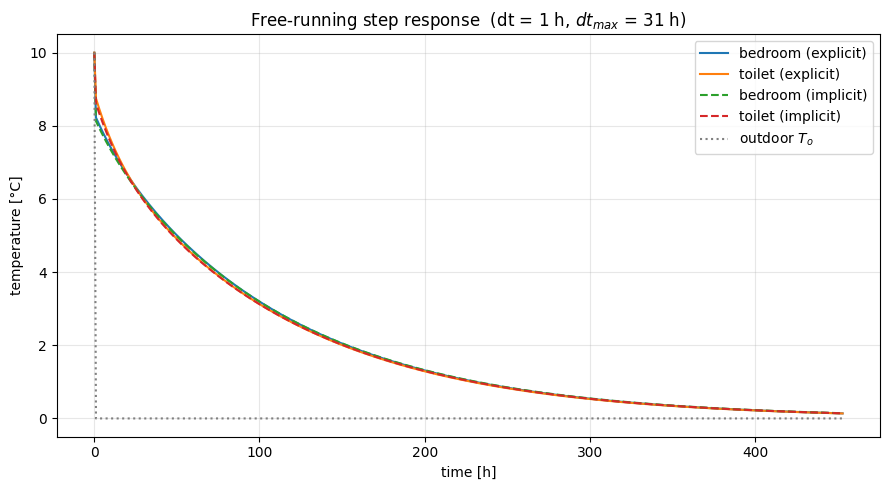

In [483]:
# 3.5 plot
th = t / 3600
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(th, ye[:, 0], label="bedroom (explicit)")
ax.plot(th, ye[:, 1], label="toilet (explicit)")
ax.plot(th, yi[:, 0], "--", label="bedroom (implicit)")
ax.plot(th, yi[:, 1], "--", label="toilet (implicit)")
ax.plot(th, To_t, ":", color="gray", label="outdoor $T_o$")
ax.set_xlabel("time [h]"); ax.set_ylabel("temperature [°C]")
ax.set_title(f"Free-running step response  (dt = {dt/3600:.0f} h, $dt_{{max}}$ = {dt_max/3600:.0f} h)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Discussion.**
- The three time constants (about 16 h, 62 h and 113 h) correspond to the three concrete walls. They are long because the walls are heavy and insulated on the outside.
- $\Delta t_{max} \approx 31$ h is very large: the model has no small capacity (air, glass), so it is not stiff. With an air capacity the fastest time constant would be of the order of minutes and the explicit method would need a much smaller time step.
- The indoor temperatures first drop quickly by about 2 °C. This part of the response is instantaneous because the air has no capacity: windows and infiltration act directly on the air node. Then the temperatures follow the slow cooling of the walls.
- With $\Delta t = 1$ h the two methods give almost the same result (maximum difference 0.14 °C). The settling time is about 19 days.

## 8. Dynamic simulation: response to weather

**Inputs.**
- Outdoor temperature and solar radiation from the weather file. The irradiance on the west and south façades is computed with `dm4bem.sol_rad_tilt_surf`.
- Solar radiation absorbed by the outer wall surfaces ($\alpha = 0.6$), absorbed by the glass ($\alpha_g = 0.38$) and transmitted through the glass ($\tau_g = 0.30$) then absorbed by the indoor wall surfaces ($\alpha = 0.25$).
- Internal gains: 100 W in the bedroom.

**Controllers.**
1. **P-controller:** always on, it heats and cools to keep 20 °C.
2. **Dead-band controller:** heating below 20 °C, no HVAC between 20 °C and 26 °C, cooling above 26 °C. At each time step the free-running temperature is computed first; the model with the controller on is used only if this temperature is outside the dead-band.

The integration uses the implicit Euler method with $\Delta t = 10$ min. Each simulation starts 7 days before the analysed week so that the initial conditions have no influence.

In [461]:
# 4.1 settings
filename = 'CHE_ZH_Wadenswil.066730_TMYx.2011-2025.epw'   # weather file, in this folder
dt4 = 600                              # time step, s (10 min)

Tsp_heat, Tsp_cool = 20.0, 26.0        # set points of the dead-band controller, °C
Qa_bed, Qa_toi = 100.0, 0.0            # internal gains, W

alpha_wall_out = 0.60                  # short-wave absorptivity, outer wall surface (assumed)
alpha_wall_in  = 0.25                  # short-wave absorptivity, indoor wall surface
alpha_glass    = 0.38                  # short-wave absorptivity of the glass
tau_glass      = 0.30                  # short-wave transmittance of the glass
f_shade        = 0.50                  # balcony slab: fraction of sun reaching the south side (assumed)
albedo         = 0.20                  # ground reflectance

In [491]:
# 4.2 weather data and solar irradiance on the west and south facades
[data, meta] = dm4bem.read_epw(filename, coerce_year=None)
weather = data[['temp_air', 'dir_n_rad', 'dif_h_rad']].copy()
weather.index = weather.index.map(lambda ts: ts.replace(year=2000))   # typical year: one common year
weather = weather.sort_index()
lat = meta['latitude']

def irradiance(azimuth):
    """Total solar irradiance on a vertical surface, W/m2 (azimuth: 0 south, 90 west)."""
    rad = dm4bem.sol_rad_tilt_surf(weather, {'slope': 90, 'azimuth': azimuth, 'latitude': lat}, albedo)
    return rad.sum(axis=1)

E_west, E_south = irradiance(90), irradiance(0)
print(f"location: {meta['city']}, latitude {lat:.2f}°")

location: Wadenswil, latitude 47.22°


In [497]:
# 4.3 inputs in time: temperature sources and flow-rate sources
S_west_b  = Lb_ns * H                  # bedroom west wall, m2
S_south_b = Lb_ew * H - S_W2           # bedroom south wall (opaque part), m2

f_names = {0: 'Phi_o_bed', 10: 'Phi_o_toi', 11: 'Phi_a_W2', 12: 'Phi_a_W4',
           2: 'Phi_i_2', 4: 'Phi_i_4', 6: 'Phi_i_6', 8: 'Phi_i_8', 3: 'Qa_bed', 7: 'Qa_toi'}

def make_inputs(t_start, t_end):
    inp = pd.DataFrame({'To': weather['temp_air'], 'E_west': E_west, 'E_south': E_south})
    inp = inp.loc[t_start:t_end].resample(f'{dt4}s').interpolate(method='linear')
    E_W2 = f_shade * inp['E_south']                                   # balcony door, behind the slab
    inp['Phi_o_bed'] = alpha_wall_out * (S_west_b * inp['E_west'] + S_south_b * f_shade * inp['E_south'])
    inp['Phi_o_toi'] = alpha_wall_out * S_ext_t * inp['E_west']
    inp['Phi_a_W2']  = alpha_glass * S_W2 * E_W2                      # absorbed by the glass
    inp['Phi_a_W4']  = alpha_glass * S_W4 * inp['E_west']
    Phi_tr_bed = tau_glass * alpha_wall_in * S_W2 * E_W2              # transmitted, absorbed by indoor walls
    Phi_tr_toi = tau_glass * alpha_wall_in * S_W4 * inp['E_west']
    inp['Phi_i_2'] = Phi_tr_bed * S_ext_b / (S_ext_b + S_shared)
    inp['Phi_i_4'] = Phi_tr_bed * S_shared / (S_ext_b + S_shared)
    inp['Phi_i_6'] = Phi_tr_toi * S_shared / (S_shared + S_ext_t)
    inp['Phi_i_8'] = Phi_tr_toi * S_ext_t / (S_shared + S_ext_t)
    inp['Qa_bed'], inp['Qa_toi'] = Qa_bed, Qa_toi
    inp['Tsp_bed'], inp['Tsp_toi'] = Tsp_heat, Tsp_heat
    return inp

In [502]:
# 4.4 simulation of one period with both controllers
def simulate(TC_base, warmup_start, start_date, end_date):
    """Implicit-Euler simulation. Returns results for start_date..end_date (warm-up discarded)."""
    inp = make_inputs(warmup_start, end_date)

    def model(Kp_bed, Kp_toi):                     # state-space with controllers ON (Kp) or OFF (0)
        TCm = {k: v.copy() for k, v in TC_base.items()}
        TCm['G']['q23'], TCm['G']['q24'] = Kp_bed, Kp_toi
        for node, name in f_names.items():
            TCm['f'][f'θ{node}'] = name
        Am, Bm, Cm, Dm, um = dm4bem.tc2ss(TCm)
        u = dm4bem.inputs_in_time(um, inp)
        A_ = Am.to_numpy()
        mm = dict(A=A_, B=Bm.to_numpy(), C=Cm.to_numpy(), D=Dm.to_numpy(), u=u.to_numpy(),
                  Minv=np.linalg.inv(np.eye(A_.shape[0]) - dt4 * A_))
        cols = list(u.columns)
        mm['i_sp'] = [cols.index(c) if c in cols else None for c in ('q23', 'q24')]
        return mm

    models = {(kb, kt): model(Kp * kb, Kp * kt) for kb in (0, 1) for kt in (0, 1)}
    n, nx = len(inp), models[1, 1]['A'].shape[0]

    def step(x, key, k, Tsp):
        mm = models[key]
        u = mm['u'][k].copy()
        for room in (0, 1):
            if mm['i_sp'][room] is not None:
                u[mm['i_sp'][room]] = Tsp[room]
        x_new = mm['Minv'] @ (x + dt4 * mm['B'] @ u)
        return x_new, mm['C'] @ x_new + mm['D'] @ u

    # controller 1: ideal P-controller, always on (heats and cools around 20 °C)
    x = np.full(nx, Tsp_heat); y_P = np.full((n, 2), Tsp_heat)
    for k in range(n - 1):
        x, y_P[k + 1] = step(x, (1, 1), k + 1, (Tsp_heat, Tsp_heat))
    q_P = Kp * (Tsp_heat - y_P)

    # controller 2: dead-band (heat below 20 °C, free-running 20-26 °C, cool above 26 °C)
    x = np.full(nx, Tsp_heat); y_DB = np.full((n, 2), Tsp_heat); q_DB = np.zeros((n, 2))
    for k in range(n - 1):
        _, y_free = step(x, (0, 0), k + 1, (Tsp_heat, Tsp_heat))      # without HVAC
        on, Tsp = [0, 0], [Tsp_heat, Tsp_heat]
        for room in (0, 1):
            if y_free[room] < Tsp_heat:
                on[room] = 1
            elif y_free[room] > Tsp_cool:
                on[room] = 1; Tsp[room] = Tsp_cool
        x, y_DB[k + 1] = step(x, tuple(on), k + 1, Tsp)
        q_DB[k + 1] = [Kp * (Tsp[r] - y_DB[k + 1, r]) * on[r] for r in (0, 1)]

    w = inp.index >= pd.Timestamp(start_date, tz=inp.index.tz)
    kWh = lambda q: float(q.sum() * dt4 / 3.6e6)
    return dict(t=inp.index[w], inp=inp[w], y_P=y_P[w], q_P=q_P[w], y_DB=y_DB[w], q_DB=q_DB[w],
                heat_P=kWh(np.clip(q_P[w], 0, None)), cool_P=kWh(np.clip(-q_P[w], 0, None)),
                heat_DB=kWh(np.clip(q_DB[w], 0, None)), cool_DB=kWh(np.clip(-q_DB[w], 0, None)))

def show(res, title):
    To_ = res['inp']['To']
    print(f"{title}: outdoor min {To_.min():.1f}, mean {To_.mean():.1f}, max {To_.max():.1f} °C")
    print(f"  P-controller: heating {res['heat_P']:.1f} kWh, cooling {res['cool_P']:.1f} kWh")
    print(f"  dead-band   : heating {res['heat_DB']:.1f} kWh, cooling {res['cool_DB']:.1f} kWh, "
          f"bedroom {res['y_DB'][:, 0].min():.1f} to {res['y_DB'][:, 0].max():.1f} °C")
    fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    axs[0].plot(res['t'], To_, color='gray', label='outdoor $T_o$')
    axs[0].plot(res['t'], res['y_DB'][:, 0], label='bedroom (dead-band)')
    axs[0].plot(res['t'], res['y_DB'][:, 1], label='toilet (dead-band)')
    axs[0].plot(res['t'], res['y_P'][:, 0], '--', lw=1, label='bedroom (P-controller)')
    axs[0].set_ylabel('temperature [°C]'); axs[0].legend(ncol=2, fontsize=8); axs[0].grid(alpha=0.3)
    axs[0].set_title(title)
    axs[1].plot(res['t'], res['inp']['E_west'], label='west façade')
    axs[1].plot(res['t'], res['inp']['E_south'], label='south façade (before slab shading)')
    axs[1].set_ylabel('solar irradiance [W/m²]'); axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3)
    axs[2].plot(res['t'], res['q_DB'][:, 0], label='bedroom (dead-band)')
    axs[2].plot(res['t'], res['q_DB'][:, 1], label='toilet (dead-band)')
    axs[2].plot(res['t'], res['q_P'][:, 0], '--', lw=1, label='bedroom (P-controller)')
    axs[2].set_ylabel('HVAC power [W]'); axs[2].legend(fontsize=8); axs[2].grid(alpha=0.3)
    fig.autofmt_xdate(); plt.tight_layout(); plt.show()

Winter week, 1 to 7 February: outdoor min -1.5, mean 1.0, max 4.4 °C
  P-controller: heating 51.9 kWh, cooling 0.0 kWh
  dead-band   : heating 51.9 kWh, cooling 0.0 kWh, bedroom 20.0 to 20.0 °C


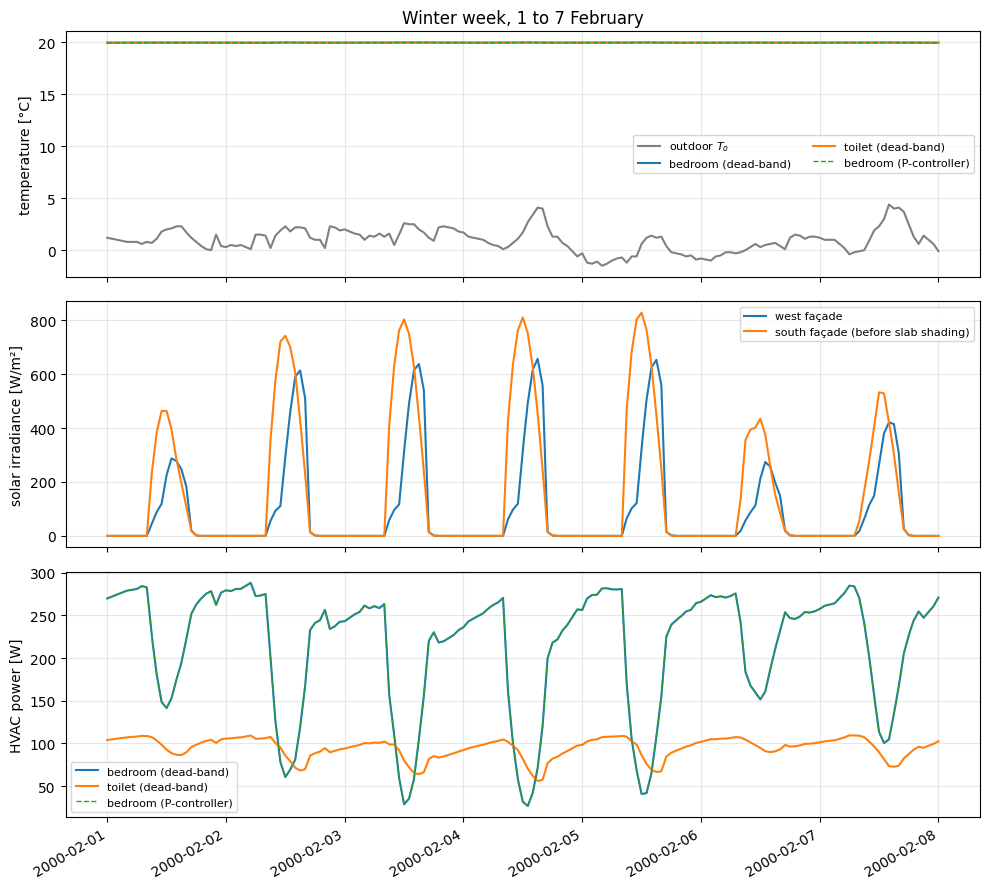

In [506]:
# 4.5 winter week: 1 to 7 February (7 days of warm-up before)
res_feb = simulate(TC, '2000-01-25 00:00', '2000-02-01 00:00', '2000-02-08 00:00')
show(res_feb, 'Winter week, 1 to 7 February')

Spring week, 1 to 7 May: outdoor min 4.4, mean 13.2, max 23.3 °C
  P-controller: heating 7.4 kWh, cooling 11.9 kWh
  dead-band   : heating 5.0 kWh, cooling 0.0 kWh, bedroom 20.0 to 24.9 °C


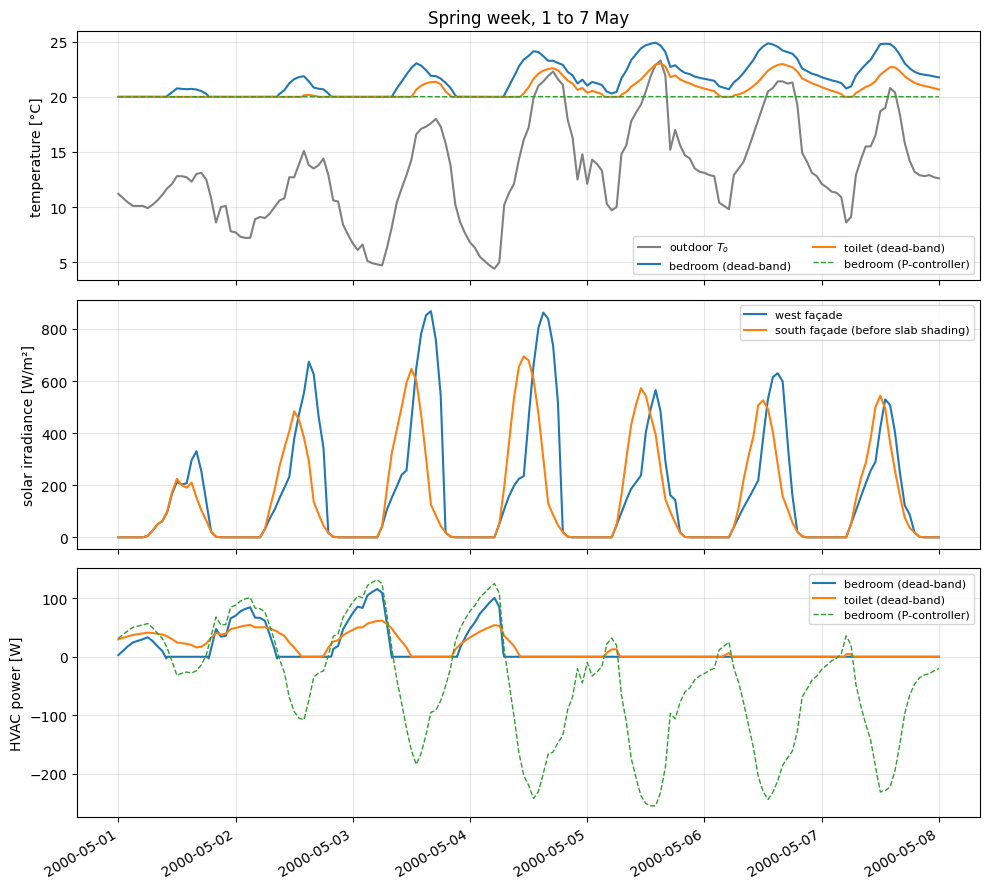

In [509]:
# 4.6 spring week: 1 to 7 May
res_may = simulate(TC, '2000-04-24 00:00', '2000-05-01 00:00', '2000-05-08 00:00')
show(res_may, 'Spring week, 1 to 7 May')

**Discussion.**
- **Winter week.** The outdoor temperature stays between −1.5 °C and 4.4 °C and heating is needed all the time, so both controllers give the same result: 51.9 kWh for the two rooms. Without sun and internal gains the mean heating power would be about 520 W; the gains reduce it to about 310 W. On sunny days the bedroom heating power drops from about 270 W to about 30 W around noon.
- **Spring week.** The P-controller heats at night and cools during the day (7.4 kWh heating, 11.9 kWh cooling). The dead-band controller lets the temperature float between 20 °C and 24.9 °C: no cooling is needed and the heating demand is lower (5.0 kWh), because the walls store the heat of the day.
- **Limits of the model.** The shading by the balcony slab is a constant factor, while a real slab shades more in summer than in winter. Only the part of the transmitted solar radiation absorbed at the first reflection is counted, so solar gains are underestimated.

## 9. Optimization

The thickness of the external insulation is varied and the heating demand of the winter week is computed for each value.

 insulation [cm]  heating, winter week [kWh]  saving vs 2 cm [%]
             2.0                        76.5                 0.0
             4.0                        62.3                18.6
             8.0                        51.9                32.2
            12.0                        47.7                37.6
            16.0                        45.5                40.5
            20.0                        44.0                42.5


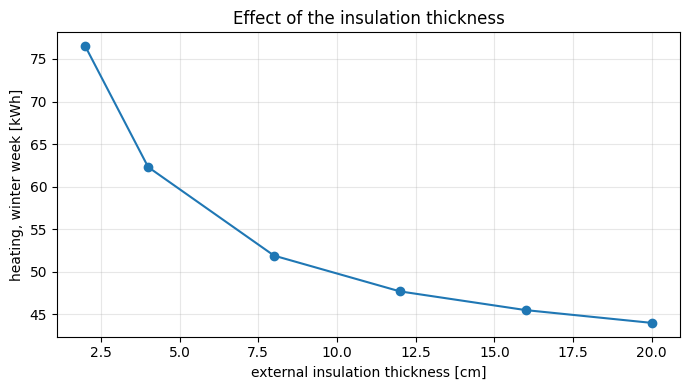

In [511]:
# 5.1 insulation thickness study (winter week, P-controller)
def TC_with_insulation(w_ins):
    """Copy of the thermal circuit with another external insulation thickness (m)."""
    TCn = {k: v.copy() for k, v in TC.items()}
    TCn['G']['q1'] = series(G_cd(insulation['lam'], w_ins, S_ext_b),
                            G_cd(concrete['lam'], w_conc_ext / 2, S_ext_b))
    TCn['G']['q10'] = series(G_cd(concrete['lam'], w_conc_ext / 2, S_ext_t),
                             G_cd(insulation['lam'], w_ins, S_ext_t))
    return TCn

thicknesses = [0.02, 0.04, 0.08, 0.12, 0.16, 0.20]          # m
heating = [simulate(TC_with_insulation(w), '2000-01-25 00:00', '2000-02-01 00:00',
                    '2000-02-08 00:00')['heat_P'] for w in thicknesses]

opt = pd.DataFrame({'insulation [cm]': [100 * w for w in thicknesses],
                    'heating, winter week [kWh]': np.round(heating, 1)})
opt['saving vs 2 cm [%]'] = np.round(100 * (1 - opt.iloc[:, 1] / opt.iloc[0, 1]), 1)
print(opt.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(opt.iloc[:, 0], opt.iloc[:, 1], 'o-')
ax.set_xlabel('external insulation thickness [cm]'); ax.set_ylabel('heating, winter week [kWh]')
ax.set_title('Effect of the insulation thickness'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Discussion.**

> **TODO (Parisa):** comment on the table and the figure. Points to address: the saving gets smaller with each added centimetre (the walls are no longer the main loss; the glazing and the infiltration are), which thickness is a reasonable choice, and what should be improved next (for example the single glazing of W4 or the double glazing of W2). Other parameters can be studied the same way: set point, infiltration rate, shading factor.

## 10. Conclusions

> **TODO:** summarise in a few sentences: the model (13 nodes, 25 branches, 3 states), the validation (free-floating check, DAE and state-space agree), the dynamics (heavy building, time constants up to 113 h), the weather results (heating demand of the winter week, effect of the dead-band controller in spring) and the result of the optimization.

## References

- C. Ghiaus, *Dynamic Models for Building Energy Management*, https://cghiaus.github.io/dm4bem_book/
- C. Ghiaus (2013). Causality issue in the heat balance method for calculating the design heating and cooling load. *Energy* 50: 292-301.
- Weather data: climate.onebuilding.org, TMYx 2011-2025, Wädenswil.